# Rotation periods beyond the TESS window: results
```
SPOC 2-min light curve (PDCSAP or SAP) --> QUALITY == 0, 30-min bins --> Lomb-Scargle peak --> compare with MEarth period
hit    = |P_peak - P_MEarth| < 0.1 x P_MEarth
chance = hit rate with MEarth periods shuffled among stars of the same period bin (1000 shuffles)
```

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image

repo = Path.cwd().parent
sys.path.insert(0, str(repo / "src"))
from plot_report import figure_pdcsap_vs_sap, figure_step5

results = repo / "results"
bins = ["<13.7", "13.7-27", ">27"]

## 1. Sample

In [2]:
sample = pd.read_csv(results / "step1_summary.csv")
sample["sample"] = sample["sample"].map({"mearth_n": "MEarth north", "mearth_s": "MEarth south", "tars": "TARS (short-period control)"})
totals = sample[sample["sample"] != "TARS (short-period control)"].groupby("period_bin")[["n_stars", "n_with_spoc_2min"]].sum().reset_index()
totals["sample"] = "MEarth total"
sample = pd.concat([sample, totals])
cells = []
for _, row in sample.iterrows():
    cell = f"{row['n_with_spoc_2min']} / {row['n_stars']}"
    if pd.notna(row["median_sectors_if_covered"]):
        cell = cell + f"  ({int(row['median_sectors_if_covered'])})"
    cells.append(cell)
sample["cell"] = cells
table = sample.pivot(index="sample", columns="period_bin", values="cell").reindex(columns=bins).fillna("-")
table.loc[["MEarth north", "MEarth south", "MEarth total", "TARS (short-period control)"]].rename_axis(columns="stars with SPOC 2-min / all  (median sectors)")

stars with SPOC 2-min / all (median sectors),<13.7,13.7-27,>27
sample,,,
MEarth north,204 / 221 (3),16 / 17 (2),132 / 139 (3)
MEarth south,89 / 98 (3),6 / 7 (2),117 / 127 (3)
MEarth total,293 / 319,22 / 24,249 / 266
TARS (short-period control),75 / 75 (2),-,-


## 2. Lomb-Scargle on PDCSAP vs SAP
All sectors of a star combined, with a free flux offset per sector. One point per star.

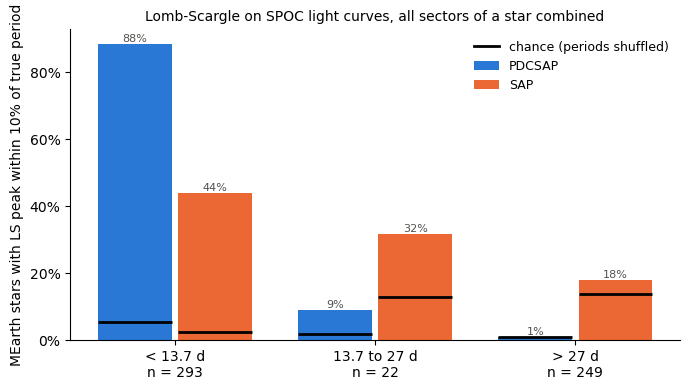

In [3]:
fig = figure_pdcsap_vs_sap()

In [4]:
counts = pd.read_csv(results / "step3_counts.csv")
counts = counts[counts["mode"] == "combined"].drop(columns="mode").set_index(["truth", "period_bin"])
counts.columns = pd.MultiIndex.from_tuples([
    ("", "stars"),
    ("period recovered by", "both"), ("period recovered by", "SAP only"), ("period recovered by", "PDCSAP only"), ("period recovered by", "neither"),
    ("LS peak at 13.7 +- 1.5 d", "PDCSAP"), ("LS peak at 13.7 +- 1.5 d", "SAP"),
])
counts

period recovered by                               \
                  stars                both SAP only PDCSAP only neither   
truth  period_bin                                                          
MEarth <13.7        293                 127        2         132      32   
       13.7-27       22                   2        5           0      15   
       >27          249                   1       44           1     203   
TARS   <13.7         75                  34        0          26      15   

                  LS peak at 13.7 +- 1.5 d      
                                    PDCSAP SAP  
truth  period_bin                               
MEarth <13.7                             1  14  
       13.7-27                           0   1  
       >27                              15  15  
TARS   <13.7                             2   2

## 3. Small GAN: forecast a sector, then extend it
```
5 folds by star: train on 4/5 of the stars, test on the stars never seen in training
(1) forecast : first 14 d of a sector --> GAN --> next 14 d                compared with flat line, fitted sinusoid
(2) extend   : last 14 d --> GAN --> +14 d --> GAN --> +14 d  -->  Lomb-Scargle on observed + 28 d generated
conv net (L1 only) = same generator, trained without the adversarial loss
```

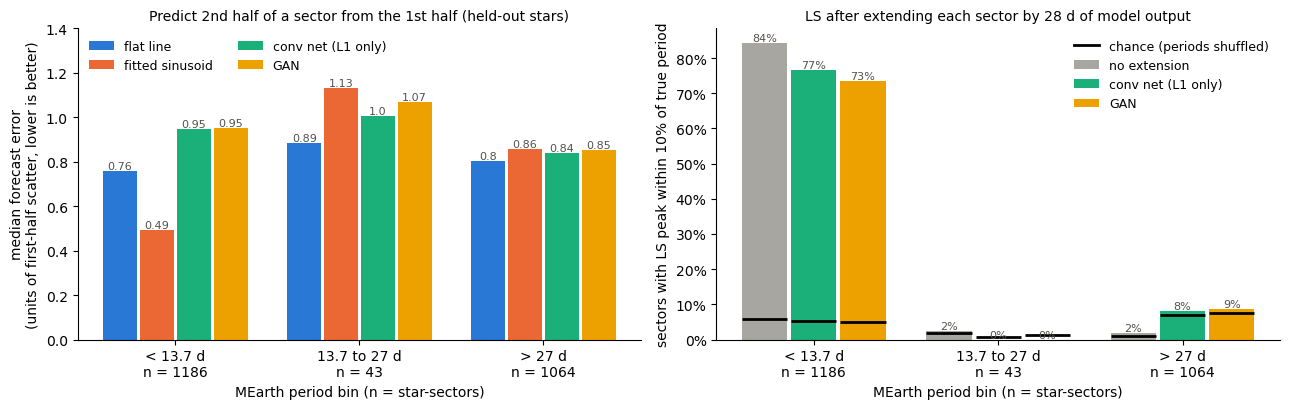

In [5]:
fig = figure_step5()

Example forecasts on held-out stars (median-error case per period bin).

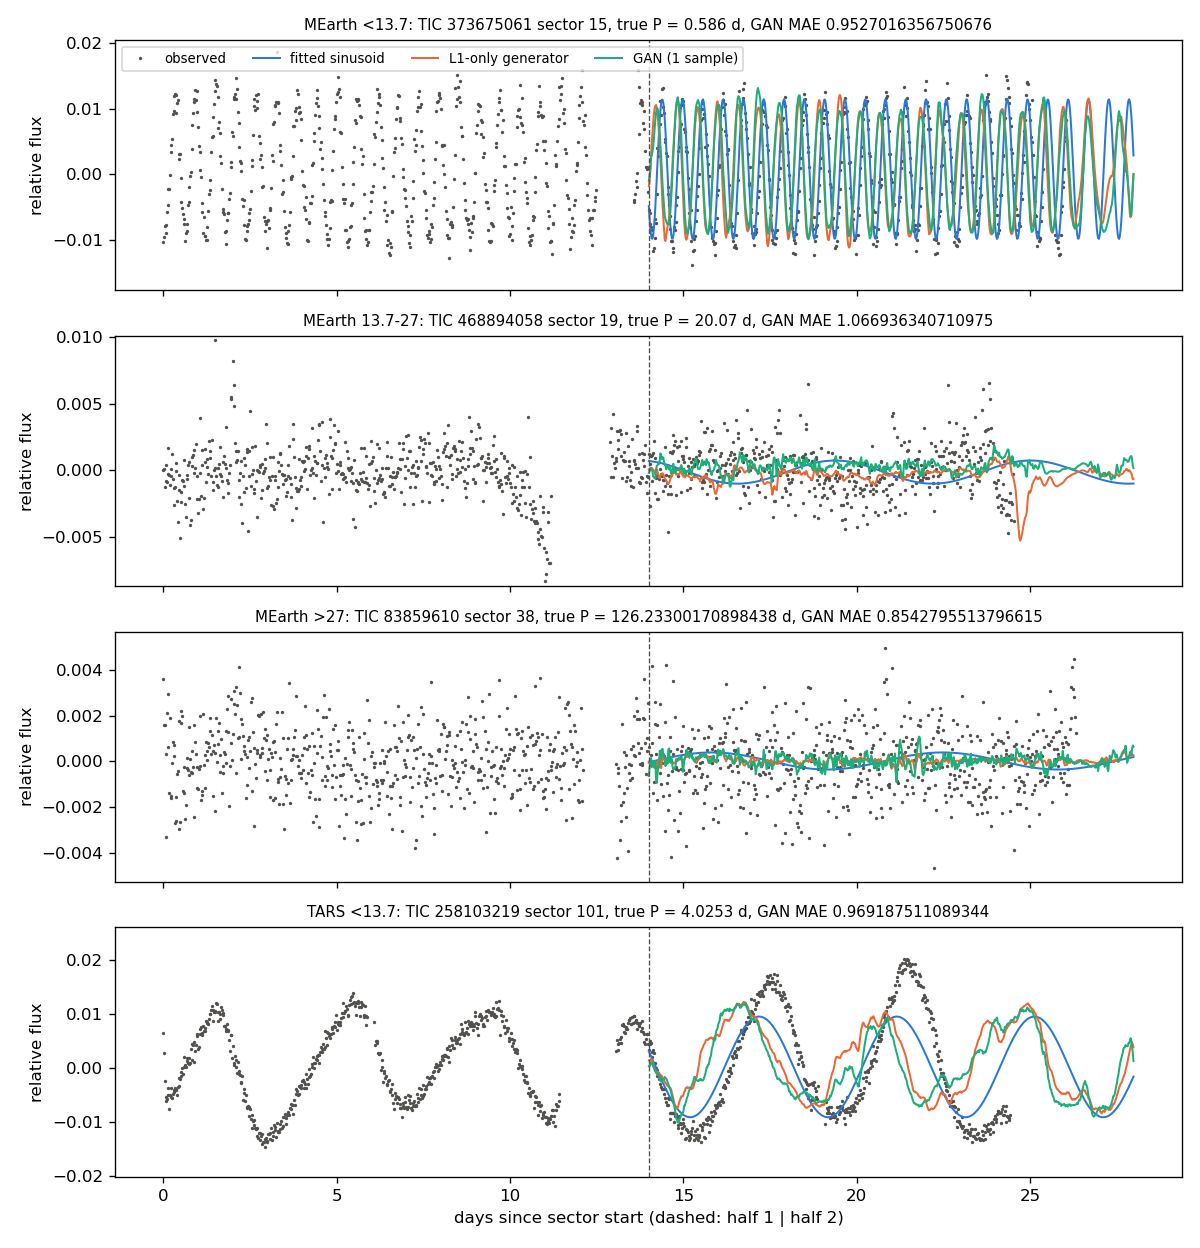

In [6]:
Image(filename=str(results / "plots" / "step5_examples.png"))

## Summary
```
PDCSAP, P > 27 d : 1% recovered = chance 1%                      --> no long-period signal left in PDCSAP
SAP,    P > 27 d : 18% vs chance 14% (p = 0.02)                  --> weak excess, but short periods drop 88% --> 44%
GAN              : worse than a flat line in every period bin;
                   extension adds no hits above chance (P > 27 d: 9% vs chance 7%, p = 0.14)
```